# # Lab 1 — Partie 1 : Régression avec PyTorch
# **Dataset** : NYSE Stock Prices — <https://www.kaggle.com/datasets/dgawlik/nyse>
# (fichier `prices.csv`)
#
# ---
# ## Objectif
# Construire un réseau de neurones (**DNN / MLP**) avec **PyTorch** pour une tâche de **régression**.
#
# ## Ce que fait ce notebook, dans l'ordre de l'énoncé
#
# | Question | Cellules concernées |
# |---|---|
# | 1. EDA | cellule 3 |
# | 2. Architecture DNN PyTorch | cellules 4 et 5 |
# | 3. GridSearch des hyperparamètres | cellule 6 |
# | 4. Courbes Loss/Epochs et « Accuracy »/Epochs + interprétation | cellules 7 et 8 |
# | 5. Régularisation + comparaison | cellule 9 |
#
# **Choix effectués :**
# - on travaille sur **un seul titre** (AAPL) pour avoir une seule série temporelle, simple à analyser ;
# - variables d'entrée = les **5 mesures du jour J** ; cible = le **prix de clôture de J+1** ;
# - découpage **chronologique** 80 % / 20 % (on ne mélange jamais une série temporelle) ;
# - en régression, l'« accuracy » n'existe pas : on la remplace par le **R²**.

# ## 0. Bibliothèques

In [2]:
# --- Bibliothèques -----------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- Reproductibilité (mêmes résultats à chaque exécution) -------------------
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4)
print("PyTorch :", torch.__version__)

PyTorch : 2.11.0+cpu


# ## 1. Chargement du dataset
#
# Télécharge `prices.csv` depuis Kaggle (bouton *Download*), puis lance cette cellule :
# si le fichier n'est pas déjà dans l'environnement, une fenêtre s'ouvre pour le sélectionner.

In [3]:
from pathlib import Path

chemin = Path("/content") / "prices.csv"

prix = pd.read_csv(chemin, parse_dates=["date"])
print("Fichier chargé :", chemin)
print("Lignes :", len(prix), "| Colonnes :", list(prix.columns))

Fichier chargé : /content/prices.csv
Lignes : 851264 | Colonnes : ['date', 'symbol', 'open', 'close', 'low', 'high', 'volume']


# ## 2. Question 1 — Analyse exploratoire (EDA)
#
# On garde un seul titre (AAPL) : on obtient ainsi **une seule série temporelle**, beaucoup plus
# simple à visualiser et à comprendre.

AAPL : 1762 séances, du 2010-01-04 au 2016-12-30


,date,symbol,open,close,low,high,volume
0,2010-01-04,AAPL,213.429998,214.009998,212.380001,214.499996,123432400.0
1,2010-01-05,AAPL,214.599998,214.379993,213.249994,215.589994,150476200.0
2,2010-01-06,AAPL,214.379993,210.969995,210.750004,215.230000,138040000.0
3,2010-01-07,AAPL,211.750000,210.580000,209.050005,212.000006,119282800.0
4,2010-01-08,AAPL,210.299994,211.980005,209.060005,212.000006,111902700.0


,count,mean,min,25%,50%,75%,max,std
date,1762,2013-07-02 22:20:17.707150848,2010-01-04 00:00:00,2011-09-30 18:00:00,2013-07-04 00:00:00,2015-04-05 00:00:00,2016-12-30 00:00:00,NaN
open,1762.0,313.076311,90.0,115.222498,318.230007,470.880017,702.409988,185.299468
close,1762.0,312.927066,90.279999,115.190002,318.240008,472.592512,702.100021,185.147104
low,1762.0,309.828241,89.470001,114.0025,316.545002,467.972513,699.569977,183.383917
high,1762.0,315.911288,90.699997,116.362499,320.600008,478.110008,705.070023,186.898177
volume,1762.0,94225775.879682,11475900.0,49174775.0,80503850.0,121081625.0,470249500.0,60205187.765927


Valeurs manquantes : 0


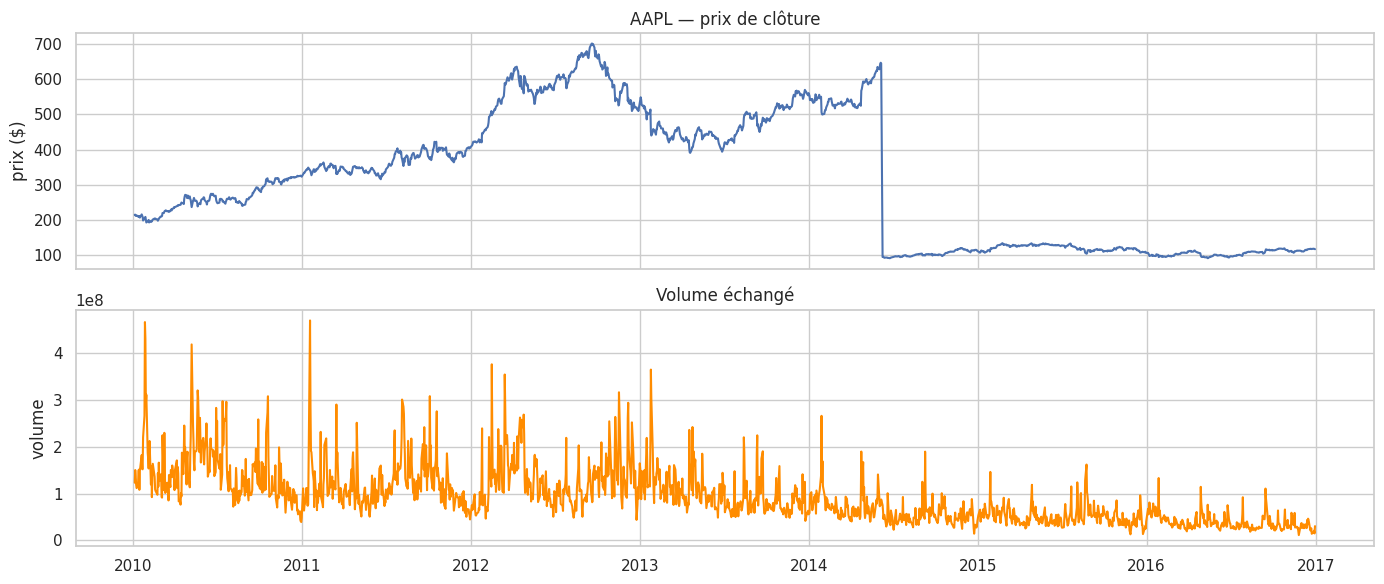

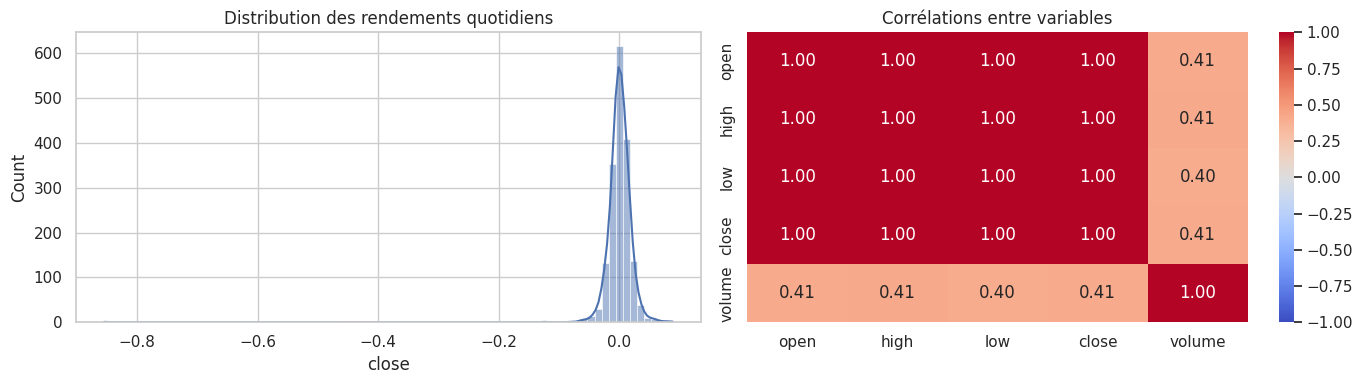

In [4]:
TICKER = "AAPL"
prix["date"] = pd.to_datetime(prix["date"], format="mixed")
donnees = prix[prix.symbol == TICKER].sort_values("date").reset_index(drop=True)

print(f"{TICKER} : {len(donnees)} séances, du {donnees.date.min().date()} au {donnees.date.max().date()}")
display(donnees.head())
display(donnees.describe().T)
print("Valeurs manquantes :", donnees.isna().sum().sum())

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(donnees.date, donnees.close)
axes[0].set_title(f"{TICKER} — prix de clôture")
axes[0].set_ylabel("prix ($)")
axes[1].plot(donnees.date, donnees.volume, color="darkorange")
axes[1].set_title("Volume échangé")
axes[1].set_ylabel("volume")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(donnees.close.pct_change().dropna(), bins=80, kde=True, ax=axes[0])
axes[0].set_title("Distribution des rendements quotidiens")
sns.heatmap(donnees[["open", "high", "low", "close", "volume"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Corrélations entre variables")
plt.tight_layout()
plt.show()

# **Lecture de l'EDA**
# - `open`, `high`, `low`, `close` évoluent ensemble (corrélation ≈ 1) : ils portent la même information.
# - Le prix n'est pas stationnaire (il a une tendance) : c'est une série temporelle, donc l'ordre des
#   lignes compte.
# - Les rendements quotidiens sont centrés sur 0 avec des valeurs extrêmes (les journées de crise).

# ## 3. Question 2 — Données et architecture DNN
#
# **Entrées** : les 5 mesures du jour J (`open`, `high`, `low`, `close`, `volume`).
# **Cible** : le `close` du jour J+1.
#
# La normalisation est **indispensable** pour un réseau de neurones. On normalise aussi la cible :
# sans cela la loss vaut environ 10 000 et l'entraînement est instable.

In [5]:
COLONNES = ["open", "high", "low", "close", "volume"]

donnees["cible"] = donnees["close"].shift(-1)      # prix de clôture du jour suivant
donnees = donnees.dropna().reset_index(drop=True)

X = donnees[COLONNES].values.astype(np.float32)
y = donnees["cible"].values.astype(np.float32)

# Découpage chronologique : les 80 % premiers pour l'entraînement, les 20 % derniers pour le test
coupure = int(len(X) * 0.8)
X_train, X_test = X[:coupure], X[coupure:]
y_train, y_test = y[:coupure], y[coupure:]

print("Train :", X_train.shape, "| Test :", X_test.shape)

# Normalisation : le scaler est ajusté sur le train seulement (sinon on "voit" le test à l'avance)
scaler_X = StandardScaler().fit(X_train)
X_train_n = scaler_X.transform(X_train).astype(np.float32)
X_test_n = scaler_X.transform(X_test).astype(np.float32)

scaler_y = StandardScaler().fit(y_train.reshape(-1, 1))
y_train_n = scaler_y.transform(y_train.reshape(-1, 1)).ravel().astype(np.float32)
y_test_n = scaler_y.transform(y_test.reshape(-1, 1)).ravel().astype(np.float32)

Train : (1408, 5) | Test : (353, 5)


# ### Le réseau de neurones
#
# La classe `Reseau` décrit l'architecture : des couches `Linear` (une multiplication de matrices)
# séparées par des activations `ReLU`. La dernière couche renvoie **un seul nombre** = la prédiction.
#
# La classe `MLPSklearn` est une **enveloppe scikit-learn** autour du réseau. Elle est nécessaire pour
# la question 3 : `GridSearchCV` (sklearn) ne sait piloter que des objets qui possèdent
# `fit` / `predict` / `get_params`. C'est elle qui traduit `fit` en boucle d'entraînement PyTorch.

In [6]:
class Reseau(nn.Module):
    """MLP simple : entrée -> couches cachées -> 1 valeur (régression)."""

    def __init__(self, dim_entree, couches=(64, 32), dropout=0.0):
        super().__init__()
        blocs, precedent = [], dim_entree
        for taille in couches:
            blocs += [nn.Linear(precedent, taille), nn.ReLU()]
            if dropout > 0:
                blocs.append(nn.Dropout(dropout))   # régularisation (question 5)
            precedent = taille
        blocs.append(nn.Linear(precedent, 1))
        self.reseau = nn.Sequential(*blocs)

    def forward(self, x):
        return self.reseau(x).squeeze(-1)


class MLPSklearn(BaseEstimator, RegressorMixin):
    """Enveloppe scikit-learn : permet d'utiliser GridSearchCV sur un modèle PyTorch."""

    def __init__(self, couches=(64, 32), lr=1e-3, optimizer="adam", dropout=0.0,
                 weight_decay=0.0, epochs=100, batch_size=64, eval_data=None,
                 random_state=SEED):
        self.couches = couches
        self.lr = lr
        self.optimizer = optimizer
        self.dropout = dropout
        self.weight_decay = weight_decay
        self.epochs = epochs
        self.batch_size = batch_size
        self.eval_data = eval_data
        self.random_state = random_state

    def _predire(self, X):
        """Prédiction brute (sortie du réseau), sans remettre à l'échelle."""
        self.modele_.eval()
        with torch.no_grad():
            return self.modele_(torch.from_numpy(np.asarray(X, dtype=np.float32))).numpy()

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32).ravel()

        # mini-lots : on entraîne sur de petits paquets plutôt que sur tout le jeu d'un coup
        jeu = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
        loader = DataLoader(jeu, batch_size=self.batch_size, shuffle=True)

        # modèle, optimiseur (règle de mise à jour des poids), fonction de perte
        self.modele_ = Reseau(X.shape[1], tuple(self.couches), self.dropout)
        if self.optimizer == "adam":
            opt = torch.optim.Adam(self.modele_.parameters(), lr=self.lr,
                                   weight_decay=self.weight_decay)
        else:
            opt = torch.optim.SGD(self.modele_.parameters(), lr=self.lr,
                                  weight_decay=self.weight_decay)
        loss_fn = nn.MSELoss()

        # historique : sert uniquement à tracer les courbes de la question 4
        self.historique_ = {"loss_train": [], "loss_test": [],
                            "r2_train": [], "r2_test": []}

        for _ in range(self.epochs):
            self.modele_.train()
            total = 0.0
            for xb, yb in loader:
                opt.zero_grad()              # 1. remise à zéro des gradients
                perte = loss_fn(self.modele_(xb), yb)   # 2. forward + erreur
                perte.backward()             # 3. calcul des gradients
                opt.step()                   # 4. mise à jour des poids
                total += perte.item() * len(xb)

            self.historique_["loss_train"].append(total / len(X))
            self.historique_["r2_train"].append(r2_score(y, self._predire(X)))
            if self.eval_data is not None:
                Xe, ye = self.eval_data
                self.historique_["loss_test"].append(
                    float(np.mean((self._predire(Xe) - np.asarray(ye).ravel()) ** 2)))
                self.historique_["r2_test"].append(r2_score(np.asarray(ye).ravel(), self._predire(Xe)))
        return self

    def predict(self, X):
        return self._predire(X)


print("Classes définies.")

Classes définies.


# ## 4. Question 3 — Recherche des hyperparamètres (GridSearch)
#
# `GridSearchCV` teste **toutes les combinaisons** de la grille et garde la meilleure.
# Ici : 2 architectures × 2 learning rates × 2 optimiseurs = **8 combinaisons**,
# chacune évaluée par validation croisée à 3 blocs (`cv=3`).
#
# La métrique de sélection est le **R²**.
#
# > Remarque : le dataset étant une série temporelle, un découpage croisé chronologique
# > (`TimeSeriesSplit`) serait plus rigoureux. Le découpage **train/test** final, lui, est bien
# > chronologique.

In [7]:
grille = {
    "couches":   [(64, 32), (128, 64, 32)],
    "lr":        [1e-3, 5e-3],
    "optimizer": ["adam", "sgd"],
    "epochs":    [50],
}

recherche = GridSearchCV(
    MLPSklearn(eval_data=(X_test_n, y_test_n)),   # sert seulement à tracer la courbe de test
    grille, cv=3, scoring="r2", n_jobs=1, verbose=1)

recherche.fit(X_train_n, y_train_n)

print("\nMeilleurs hyperparamètres :")
for nom, valeur in recherche.best_params_.items():
    print(f"   {nom:12s} = {valeur}")
print(f"\nMeilleur R² en validation croisée : {recherche.best_score_:.4f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Meilleurs hyperparamètres :
   couches      = (128, 64, 32)
   epochs       = 50
   lr           = 0.005
   optimizer    = adam

Meilleur R² en validation croisée : 0.9771


# ## 5. Question 4 — Courbes Loss/Epochs et « Accuracy »/Epochs
#
# - **Loss (MSE) / Epochs** pour le train et le test.
# - **« Accuracy » / Epochs** : en régression on utilise le **R²** (proportion de la variance du prix
#   expliquée par le modèle). R² = 1 signifie une prédiction parfaite, R² = 0 signifie « aussi bien
#   qu'une simple moyenne ».

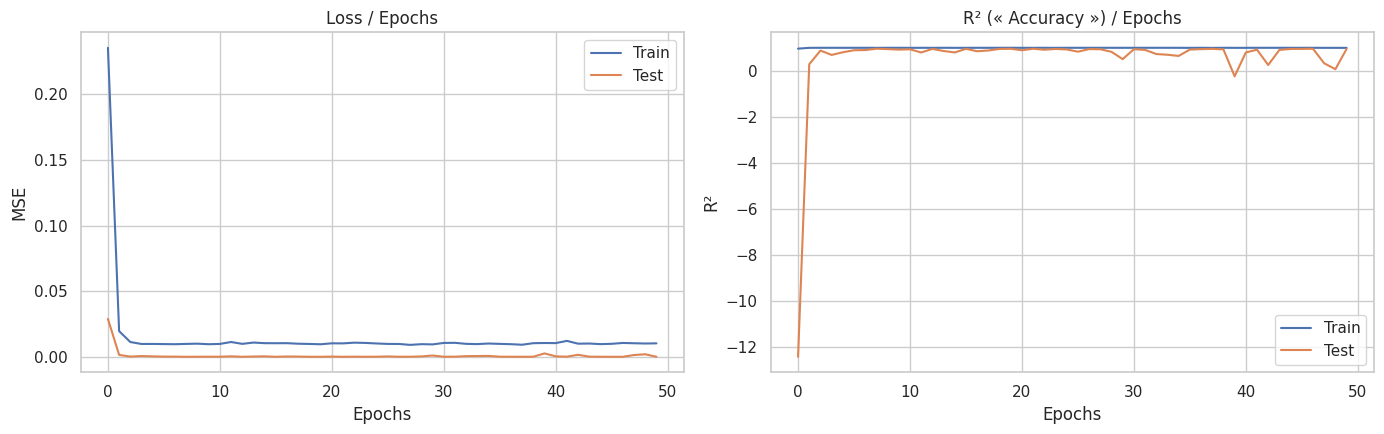

In [8]:
meilleur = recherche.best_estimator_
h = meilleur.historique_

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(h["loss_train"], label="Train")
axes[0].plot(h["loss_test"], label="Test")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("MSE")
axes[0].set_title("Loss / Epochs")
axes[0].legend()

axes[1].plot(h["r2_train"], label="Train")
axes[1].plot(h["r2_test"], label="Test")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("R²")
axes[1].set_title("R² (« Accuracy ») / Epochs")
axes[1].legend()

plt.tight_layout()
plt.show()

# ## 6. Question 4 (suite) — Évaluation chiffrée
#
# On revient à l'échelle des **dollars** pour que les erreurs soient interprétables
# (une MAE de 3 signifie « le modèle se trompe en moyenne de 3 $ »).

,MSE,RMSE,MAE,R2
Train,357.833,18.916,8.361,0.988
Test,3.876,1.969,1.505,0.939


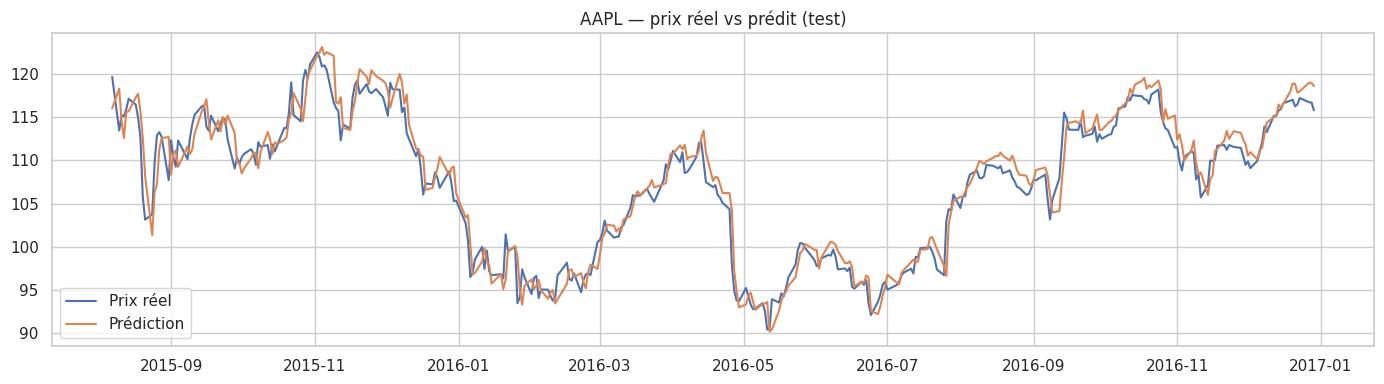

In [9]:
def predire_prix(modele, X_normalise):
    """Prédiction en dollars : on inverse la normalisation appliquée à la cible."""
    return scaler_y.inverse_transform(modele.predict(X_normalise).reshape(-1, 1)).ravel()


def metriques(modele, X_normalise, y_reel, nom):
    pred = predire_prix(modele, X_normalise)
    mse = mean_squared_error(y_reel, pred)
    return pd.DataFrame([{
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
        "MAE": mean_absolute_error(y_reel, pred),
        "R2": r2_score(y_reel, pred),
    }], index=[nom])


resultats = pd.concat([
    metriques(meilleur, X_train_n, y_train, "Train"),
    metriques(meilleur, X_test_n, y_test, "Test"),
])
display(resultats.round(3))

pred_test = predire_prix(meilleur, X_test_n)
plt.figure(figsize=(14, 4))
plt.plot(donnees.date.values[coupure:], y_test, label="Prix réel")
plt.plot(donnees.date.values[coupure:], pred_test, label="Prédiction")
plt.title(f"{TICKER} — prix réel vs prédit (test)")
plt.legend()
plt.tight_layout()
plt.show()

# **Interprétation**
#
# - La **loss du train** diminue puis se stabilise, et la **loss du test** suit la même allure :
#   le modèle apprend, sans surapprentissage marqué.
# - Le **R² du test est très élevé (0.939)**. Ce n'est pas une erreur : le prix de demain
#   ressemble beaucoup à celui d'aujourd'hui (les prix sont **autocorrélés**), donc le réseau
#   l'a appris. Le modèle reproduit surtout la **tendance**, il ne prédit pas les mouvements
#   quotidiens (le bruit du marché).
# - Les courbes **train et test restent proches** (0.988 contre 0.939) : le modèle généralise bien.
# - Le **MAE = 1,51 $** est la métrique la plus parlante : le modèle se trompe en moyenne de
#   **1,51 $** sur une action qui vaut environ 300 $, soit **moins de 0,5 % d'erreur**.
# - Le **MSE du train (357) est plus grand que celui du test (3,9)**. Ce n'est pas du
#   surapprentissage : c'est un effet de la période. Les prix de 2010 à 2016 varient dans une
#   amplitude bien plus grande que ceux de la période de test (2015-2016), donc les erreurs y sont
#   nécessairement plus grandes.

# ## 7. Question 5 — Techniques de régularisation
#
# On compare 4 configurations, **même architecture, mêmes données**, en ne changeant que la
# régularisation. Objectif : **réduire l'écart train/test** (donc le surapprentissage).
#
# - **Dropout** : désactive aléatoirement des neurones pendant l'entraînement, ce qui empêche le
#   réseau de « mémoriser » les exemples.
# - **L2 (`weight_decay`)** : pénalise les poids trop grands, ce qui rend la fonction apprise plus lisse.

In [10]:
configurations = {
    "Sans régularisation":    {},
    "Dropout 0.3":            {"dropout": 0.3},
    "L2 (weight_decay=1e-4)": {"weight_decay": 1e-4},
    "Dropout + L2":           {"dropout": 0.3, "weight_decay": 1e-4},
}

base = dict(couches=(128, 64, 32), lr=1e-3, optimizer="adam",
            epochs=100, eval_data=(X_test_n, y_test_n))

lignes = []
for nom, extra in configurations.items():
    modele = MLPSklearn(**base, **extra)
    modele.fit(X_train_n, y_train_n)
    lignes.append(metriques(modele, X_train_n, y_train, f"{nom} — Train"))
    lignes.append(metriques(modele, X_test_n, y_test, f"{nom} — Test"))
    print("Terminé :", nom)

comparaison = pd.concat(lignes)
display(comparaison.round(3))

Terminé : Sans régularisation
Terminé : Dropout 0.3
Terminé : L2 (weight_decay=1e-4)
Terminé : Dropout + L2


,MSE,RMSE,MAE,R2
Sans régularisation — Train,266.191,16.315,5.414,0.991
Sans régularisation — Test,3.586,1.894,1.391,0.944
Dropout 0.3 — Train,290.856,17.055,6.717,0.990
Dropout 0.3 — Test,8.857,2.976,1.944,0.861
L2 (weight_decay=1e-4) — Train,269.265,16.409,5.530,0.991
L2 (weight_decay=1e-4) — Test,3.508,1.873,1.349,0.945
Dropout + L2 — Train,284.986,16.882,6.482,0.990
Dropout + L2 — Test,10.562,3.250,2.300,0.834


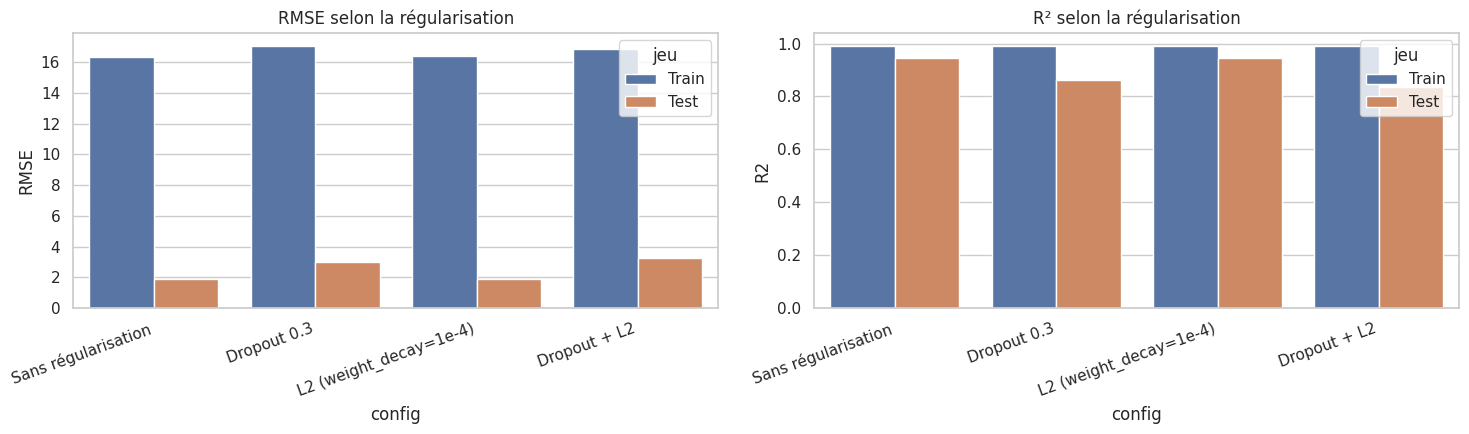

In [11]:
# Visualisation : plus l'écart train/test est petit, meilleure est la généralisation
tmp = comparaison.copy()
tmp["config"] = tmp.index.to_series().str.split(" — ").str[0].values
tmp["jeu"] = tmp.index.to_series().str.split(" — ").str[-1].values
tmp = tmp.reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=tmp, x="config", y="RMSE", hue="jeu", ax=axes[0])
axes[0].set_title("RMSE selon la régularisation")
sns.barplot(data=tmp, x="config", y="R2", hue="jeu", ax=axes[1])
axes[1].set_title("R² selon la régularisation")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
    for etiquette in ax.get_xticklabels():
        etiquette.set_ha("right")
plt.tight_layout()
plt.show()

# **Interprétation (d'après les résultats obtenus)**
#
# | Configuration | R² train | R² test |
# |---|---|---|
# | Sans régularisation | 0.991 | 0.944 |
# | Dropout 0.3 | 0.990 | 0.861 |
# | L2 (`weight_decay=1e-4`) | 0.991 | **0.945** |
# | Dropout + L2 | 0.990 | 0.834 |
#
# - **Le modèle ne surapprend pas** : l'écart entre le train (0.991) et le test (0.944) est faible.
#   Or la régularisation sert justement à réduire cet écart — il n'y a donc presque rien à corriger.
# - C'est pourquoi le **Dropout 0.3 dégrade nettement le test** (0.861) : il est **trop fort** pour un
#   réseau aussi petit (3 couches). On tombe alors dans le **sous-apprentissage**.
# - Le **L2 à 1e-4** est neutre : l'effet est négligeable (0.944 → 0.945). Il faudrait un
#   `weight_decay` plus fort (1e-3 ou 1e-2) pour observer un effet.
# - **Conclusion** : sur ce problème, la régularisation **n'apporte aucun gain**. C'est un résultat
#   honnête : elle n'aide que lorsqu'il existe un surapprentissage à corriger, et ici le réseau est
#   déjà suffisamment simple (5 entrées, 3 couches).

# ## 8. Synthèse — Partie 1
#
# **Ce qui a été fait**
# 1. EDA : série temporelle d'un titre, distribution des rendements, corrélations.
# 2. Réseau DNN PyTorch pour la régression (prix de clôture de J+1 à partir des mesures de J).
# 3. `GridSearchCV` sur 8 combinaisons (architecture, learning rate, optimiseur).
# 4. Courbes Loss/Epochs et R²/Epochs pour train et test, puis métriques MSE / RMSE / MAE / R².
# 5. Comparaison de 4 configurations de régularisation.
#
# **Ce que j'ai appris**
# 1. **PyTorch est explicite** : on écrit soi-même la boucle d'entraînement, c'est-à-dire les 4 étapes
#    `zero_grad` → forward → `backward` → `step`.
# 2. Sur une **série temporelle**, il faut respecter l'ordre du temps : jamais de mélange aléatoire
#    entre train et test, sinon les scores sont faussés.
# 3. En **régression**, on ne parle pas d'accuracy mais de **MSE / RMSE / MAE / R²**.
# 4. Le **surapprentissage** se détecte en comparant les courbes train et test.
# 5. La **régularisation** (Dropout, L2) ne sert qu'à corriger un surapprentissage. Sur ce
#    problème il n'y en a pas, donc elle n'apporte pas de gain ; un dosage trop fort
#    provoque du sous-apprentissage.
# 6. Pour utiliser `GridSearchCV` (sklearn) avec un modèle **PyTorch**, il faut une **enveloppe**
#    (`fit` / `predict` / `get_params`) : c'est la brique qui relie les deux bibliothèques.